In [2]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals, bh_projections
import importlib
import scipy

In [10]:
importlib.reload(transforms)
M = 127
sigma = 2
nz = M

## theta and phi grids used for radon transform
thetas = np.linspace(0, np.pi, M, endpoint=True)
phis = np.linspace(0, 2*np.pi, M, endpoint=False)



f = utils.generate_centered_gaussian(M, d=3, sigma=sigma)
f_1 = transforms.translate_3d(f, 0, 10, 0)     # move centered blob down
f_2 = transforms.translate_3d(f, 0, -15, -20)  # move blob far left and up
f_3 = transforms.translate_3d(f, 0, 0, 10)    # move blob back and right
F = f_1 + f_2 + f_3
F = signals.Signal(F, d=3).preprocess_signals()[0]



## compute Radon transform
Pf = transforms.Transform(F, d=3).radon_transform()[0]


#rotation Euler angles in ZYZ convention
omega = 1*np.deg2rad(np.random.randint(0,360))
alpha = 1*np.deg2rad(np.random.randint(0,360))#np.random.randint(0,M-1)*np.pi/M##0*np.deg2rad(np.random.randint(0,180))
beta = 1*np.deg2rad(np.random.randint(0,180))#5*2*np.pi/M#1*np.deg2rad(np.random.randint(0,360))

b_idx = np.argmin(abs(thetas - abs(beta)))
a_idx = np.argmin(abs(phis - abs(alpha)))

#rotate F by the angles above
# print(np.linalg.norm(F))
G = transforms.rotate_voxel_zyz(F, omega, beta, alpha, order=1)
Gfourier = transforms.rotate_voxel_zyz_fourier(F, omega, beta, alpha, order=1)



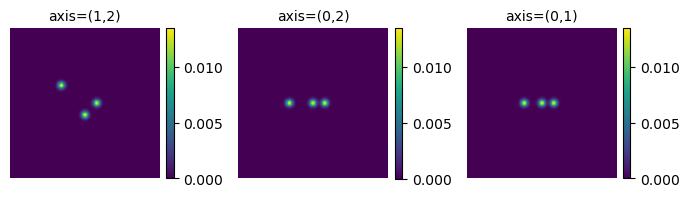

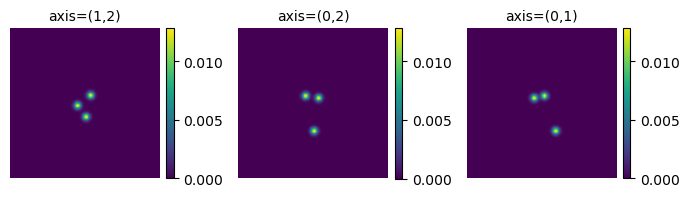

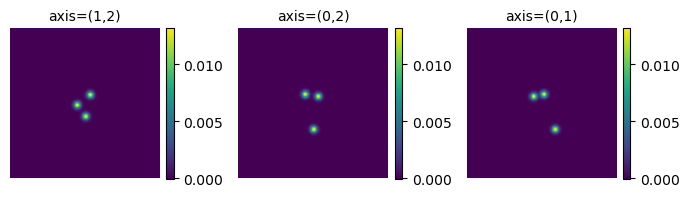

0.49789395996963276


In [11]:
plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(G)
plots.orthogonal_2D_projection_plot(Gfourier)
print(np.linalg.norm(G-Gfourier)/np.linalg.norm(G))

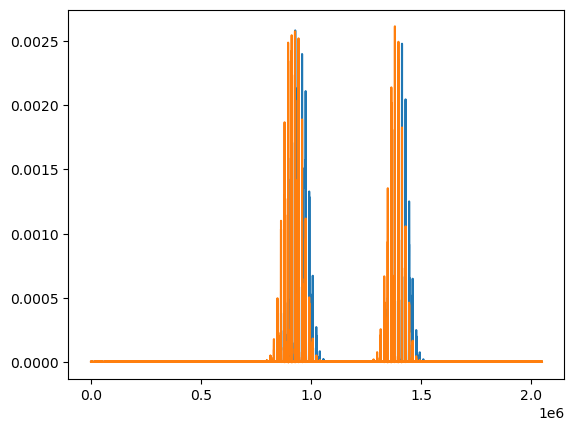

In [12]:
plt.plot(G.flatten())
plt.plot(Gfourier.flatten())


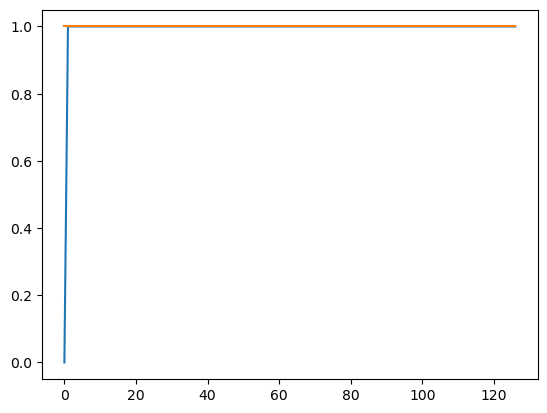

In [19]:
importlib.reload(transforms)
M = 127
sigma = 2
nz = M

## theta and phi grids used for radon transform
thetas = np.linspace(0, np.pi, M, endpoint=True)
phis = np.linspace(0, 2*np.pi, M, endpoint=False)



f = utils.generate_centered_gaussian(M, d=3, sigma=sigma)
f_1 = transforms.translate_3d(f, 0, 0, 54)     # move centered blob down
F = 0*f_1
F[M//2, M//2, :] = 1

#rotation Euler angles in ZYZ convention
omega = 0
alpha = 0
beta = np.pi/2

b_idx = np.argmin(abs(thetas - abs(beta)))
a_idx = np.argmin(abs(phis - abs(alpha)))

#rotate F by the angles above
# print(np.linalg.norm(F))
G = transforms.rotate_voxel_zyz(F, omega, beta, alpha, order=1)
Gfourier = transforms.rotate_voxel_zyz_fourier(F, omega, beta, alpha, order=1)

plt.plot(G[:,M//2,M//2])
plt.plot(Gfourier[:,M//2,M//2])

In [ ]:
### EV: add small test to look at residual from applying rotation and inverse
###     looks much better in Fourier version

# A1 = transforms.rotate_voxel_zyz(F, omega, beta, alpha, order=1)
# A1_r = transforms.rotate_voxel_zyz(A1, -alpha, -beta, -omega, order=1)

# A2 = transforms.rotate_voxel_zyz_fourier(F, omega, beta, alpha)
# A2_r = transforms.rotate_voxel_zyz_fourier(A2, -alpha, -beta, -omega)


# print(np.linalg.norm(F - A1_r))

# print(np.linalg.norm(F - A2_r))


# plots.orthogonal_2D_projection_plot(F-A1_r)

# plots.orthogonal_2D_projection_plot(F-A2_r)